# 05 · La historia de Jardine: con balón, sin balón, forma defensiva (360) y balón parado

**Qué responde** (todo.md §3.2, §3.3, §3.4 y §3.8): cómo sale, por dónde progresa y cómo genera ocasiones el América de
André Jardine; dónde y cómo recupera el balón, cuánto presiona y cómo le va en las transiciones; y, con 360, qué tan alto
y qué tan junto defiende; y cómo ataca y defiende el balón parado. Siempre
**frente a Solari y Ortiz** (el "antes") y, donde existe la métrica para toda la liga, **frente a la Liga MX**.

**Reglas del notebook**
- **Muestra**: toda cifra sale de la **ventana oficial (Apertura 2021 – Clausura 2025)**: Jardine 91 partidos,
  Ortiz 55, Solari 27. Validación (Ap 2025) y prueba (2026) no entran aquí.
- **Definiciones**: posesión, transición, recuperación, pase progresivo, zonas y umbrales vienen de `src/framework.py`
  (`ASSUMPTIONS`); este notebook no redefine nada. Los cálculos viven en `src/story.py` y las canchas en
  `src/story_viz.py`, que también consumirá el reporte HTML.
- **Datos**: los eventos solo se usan en memoria. A disco van **solo agregados** (`data/gold/analysis/story_*.parquet`)
  y figuras (`reports/figures/story/`).
- **Cancha**: 120 × 80 yardas, el América ataca hacia la derecha y su banda izquierda queda arriba.

Cada bloque cierra con **una pregunta de fútbol, un hallazgo con número y 1–2 canchas**.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from src import story as S, story_viz as V
from src.pipeline.config import GOLD

pd.set_option("display.max_columns", 30, "display.width", 250, "display.float_format", lambda v: f"{v:,.2f}")
FIG = ROOT / "reports" / "figures" / "story"; FIG.mkdir(parents=True, exist_ok=True)

def save(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=140, bbox_inches="tight"); plt.show()

H = []  # hallazgos del notebook: bloque, pregunta, hallazgo, figuras (se guardan al final)
def finding(bloque, pregunta, texto, figuras):
    H.append({"bloque": bloque, "pregunta": pregunta, "hallazgo": texto, "figuras": ", ".join(figuras)})
    display(Markdown(f"**{pregunta}**\n\n**Hallazgo.** {texto}"))

dim = pd.read_parquet(GOLD / "dim_match.parquet")
scope = S.match_scope(dim)                  # ventana oficial · Solari / Ortiz / Jardine
ev = S.load_story_events(scope)             # eventos: SOLO en memoria
poss = S.load_possessions(scope)            # fct_possession (Gold)
mf = pd.read_parquet(GOLD / "match_features.parquet")
tml = pd.read_parquet(GOLD / "fct_team_match_league.parquet")
assert set(scope.split) == {"train"}
S.n_matches(scope).to_frame().T

coach,Solari,Ortiz,Jardine
partidos,27,55,91


## 3.2 Con balón

### a) ¿Cómo sale desde atrás?

Se miran los **saques de meta** y los **pases del portero en juego**. *Corto* = menos de 32 yardas (umbral del marco,
`long_pass_yd`). Para cada salida: dónde cae el balón (tercio × carril), quién lo recibe (línea del receptor, si el pase
llega) y qué pasa después con la jugada (¿llega a campo rival? ¿termina en tiro?).

In [2]:
r = S.restarts(ev)                                   # en memoria
rs = S.restart_summary(r, scope)
ro = S.restart_outcomes(r, poss)
rr = S.restart_receivers(r)
zones = S.zone_grid(r, "pass_end_location_x", "pass_end_location_y", ["coach", "kind"])
display(rs, ro)
display((rr[rr.length == "Corto"].pivot_table(index=["kind", "receiver_group"], columns="coach", values="share") * 100)
        .round(0)[S.COACHES])
for df, name in [(rs, "salida_resumen"), (ro, "salida_resultado"), (rr, "salida_receptor"), (zones, "salida_zonas")]:
    S.save_story(df, name)

,coach,kind,n,pct_corto,pct_completo_corto,pct_completo_largo,por_partido
0,Jardine,Portero en juego,1970,53.76,99.06,56.86,21.65
1,Jardine,Saque de meta,759,45.45,100.00,49.76,8.34
2,Ortiz,Portero en juego,1048,51.53,98.52,50.00,19.05
3,Ortiz,Saque de meta,425,31.29,100.00,46.23,7.73
4,Solari,Portero en juego,610,51.48,99.04,54.73,22.59
5,Solari,Saque de meta,208,33.17,100.00,45.32,7.70


,coach,kind,length,n,pct_llega_campo_rival,pct_tiro,xg_por_100
0,Jardine,Portero en juego,Corto,1059,79.60,9.35,1.25
1,Jardine,Portero en juego,Largo,911,73.77,7.90,0.92
2,Jardine,Saque de meta,Corto,345,65.51,5.80,0.72
3,Jardine,Saque de meta,Largo,414,73.91,5.31,0.68
4,Ortiz,Portero en juego,Corto,540,85.93,13.15,1.96
5,Ortiz,Portero en juego,Largo,508,78.94,9.06,1.10
6,Ortiz,Saque de meta,Corto,133,77.44,11.28,2.04
7,Ortiz,Saque de meta,Largo,292,80.14,4.11,0.56
8,Solari,Portero en juego,Corto,314,83.76,7.96,0.58
9,Solari,Portero en juego,Largo,296,83.78,7.77,0.78


coach                             Solari  Ortiz  Jardine
kind             receiver_group                         
Portero en juego Banda              2.00   2.00     2.00
                 Carrilero           NaN    NaN     1.00
                 Defensa           86.00  76.00    77.00
                 Delantero          1.00   0.00     1.00
                 Medio              1.00   1.00     2.00
                 Medio defensivo   10.00  21.00    17.00
                 Medio ofensivo     1.00   1.00     1.00
Saque de meta    Banda              1.00    NaN     2.00
                 Carrilero           NaN    NaN     0.00
                 Defensa           93.00  75.00    44.00
                 Delantero          1.00    NaN     1.00
                 Medio               NaN    NaN     1.00
                 Medio defensivo    4.00  20.00    44.00
                 Medio ofensivo      NaN   1.00     0.00
                 Portero             NaN   5.00     8.00

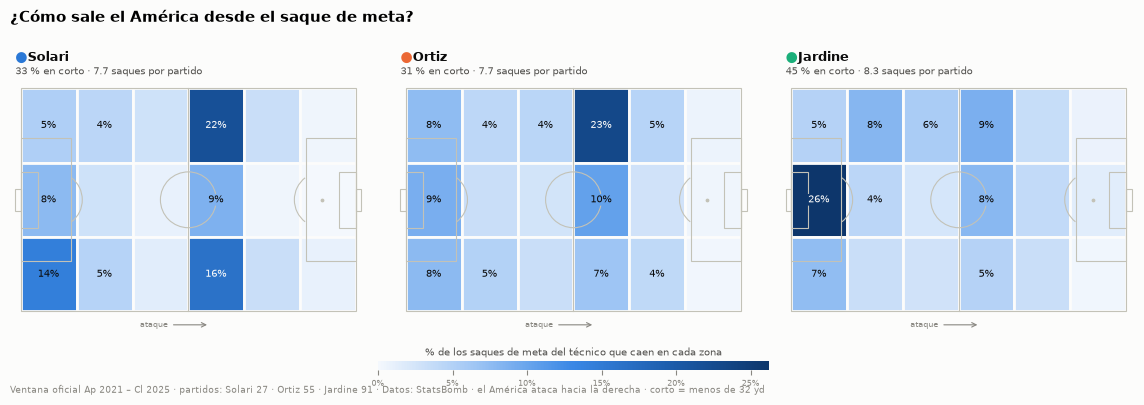

In [3]:
save(V.fig_goal_kicks(zones[zones.kind == "Saque de meta"], rs, scope,
                      "¿Cómo sale el América desde el saque de meta?"), "salida_saque_meta")

In [4]:
gk = rs[rs.kind == "Saque de meta"].set_index("coach")
kp = rs[rs.kind == "Portero en juego"].set_index("coach")
rec = (rr[(rr.kind == "Saque de meta") & (rr.length == "Corto")]
       .pivot(index="receiver_group", columns="coach", values="share").fillna(0) * 100)
out = ro[ro.kind == "Saque de meta"].set_index(["coach", "length"])
finding("3.2a Salida", "¿Cómo sale el América desde atrás?",
    f"Con Jardine el América sale jugando: saca en corto el {gk.loc['Jardine', 'pct_corto']:.0f} % de sus saques de meta, "
    f"frente a {gk.loc['Ortiz', 'pct_corto']:.0f} % con Ortiz y {gk.loc['Solari', 'pct_corto']:.0f} % con Solari. "
    f"Ese pase corto lo recibe un mediocentro que baja a pedirla en el {rec.loc['Medio defensivo', 'Jardine']:.0f} % de los casos "
    f"(Ortiz {rec.loc['Medio defensivo', 'Ortiz']:.0f} %, Solari {rec.loc['Medio defensivo', 'Solari']:.0f} %, que se la daban "
    f"casi siempre a un central). Es una idea de control, no un atajo al gol: "
    f"{out.loc[('Jardine', 'Corto'), 'pct_llega_campo_rival']:.0f} % de esas salidas cortas llega a campo rival "
    f"(Ortiz {out.loc[('Ortiz', 'Corto'), 'pct_llega_campo_rival']:.0f} %; en largo, "
    f"{out.loc[('Jardine', 'Largo'), 'pct_llega_campo_rival']:.0f} %) y generan "
    f"{out.loc[('Jardine', 'Corto'), 'xg_por_100']:.1f} xG por cada 100 salidas, "
    + ("lo mismo que en largo." if round(out.loc[('Jardine', 'Corto'), 'xg_por_100'], 1) == round(out.loc[('Jardine', 'Largo'), 'xg_por_100'], 1)
       else f"frente a {out.loc[('Jardine', 'Largo'), 'xg_por_100']:.1f} en largo."),
    ["salida_saque_meta.png"])

**¿Cómo sale el América desde atrás?**

**Hallazgo.** Con Jardine el América sale jugando: saca en corto el 45 % de sus saques de meta, frente a 31 % con Ortiz y 33 % con Solari. Ese pase corto lo recibe un mediocentro que baja a pedirla en el 44 % de los casos (Ortiz 20 %, Solari 4 %, que se la daban casi siempre a un central). Es una idea de control, no un atajo al gol: 66 % de esas salidas cortas llega a campo rival (Ortiz 77 %; en largo, 74 %) y generan 0.7 xG por cada 100 salidas, lo mismo que en largo.

### b) ¿Por dónde progresa?

**Acciones progresivas** (marco): pases completos y conducciones que acercan el balón al menos 25 % a la portería rival y
terminan en x ≥ 48. Se cuentan por el **carril donde terminan** (izquierdo, central, derecho: tercios del ancho).
**Entradas**: pases completos de juego abierto o conducciones que cruzan al último tercio (x < 80 → x ≥ 80) o que
entran al área desde fuera.

In [5]:
pa = S.progressive_actions(ev)                      # en memoria
prog = S.progression_by_lane(pa, scope)
en = S.entries(ev)                                  # en memoria
ents = S.entry_summary(en, scope)
box_grid = S.grid_per_match(S.zone_grid(en[en.box], "ex", "ey", ["coach"], x_bins=[102, 108, 114, 120],
                                        y_bins=[18, 30, 50, 62.01]), scope)
display((prog.pivot_table(index=["action", "lane"], columns="coach", values="share") * 100).round(0)[S.COACHES])
display(ents.pivot_table(index=["entrada", "lane"], columns="coach", values="por_partido", aggfunc="sum")[S.COACHES])
display(ents.pivot_table(index=["entrada", "method"], columns="coach", values="por_partido", aggfunc="sum")[S.COACHES])
for df, name in [(prog, "progresion_carril"), (ents, "entradas"), (box_grid, "entradas_area_zonas")]:
    S.save_story(df, name)

coach                            Solari  Ortiz  Jardine
action                lane                             
Conducción progresiva Central     23.00  35.00    31.00
                      Derecho     30.00  24.00    31.00
                      Izquierdo   47.00  40.00    38.00
Pase progresivo       Central     36.00  46.00    42.00
                      Derecho     35.00  25.00    26.00
                      Izquierdo   28.00  29.00    32.00

coach                    Solari  Ortiz  Jardine
entrada       lane                             
Área          Central      4.78   6.42     5.92
              Derecho      2.00   3.55     3.82
              Izquierdo    3.15   5.05     4.93
Último tercio Central      5.67  11.73     9.25
              Derecho     14.85  17.05    17.90
              Izquierdo   16.81  20.47    21.05

coach                     Solari  Ortiz  Jardine
entrada       method                            
Área          Centro        2.93   2.78     2.12
              Conducción    3.56   5.78     5.96
              Pase          3.44   6.45     6.60
Último tercio Conducción   14.70  17.98    18.44
              Pase         22.63  31.27    29.77

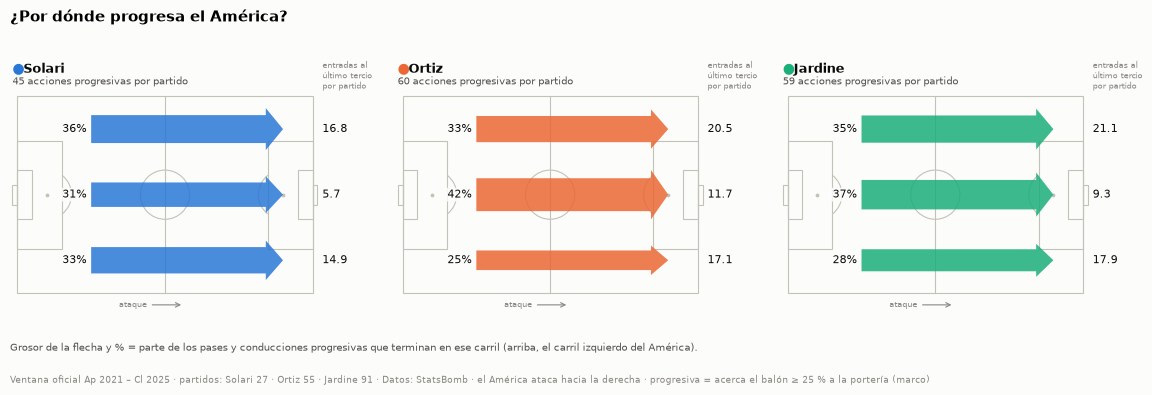

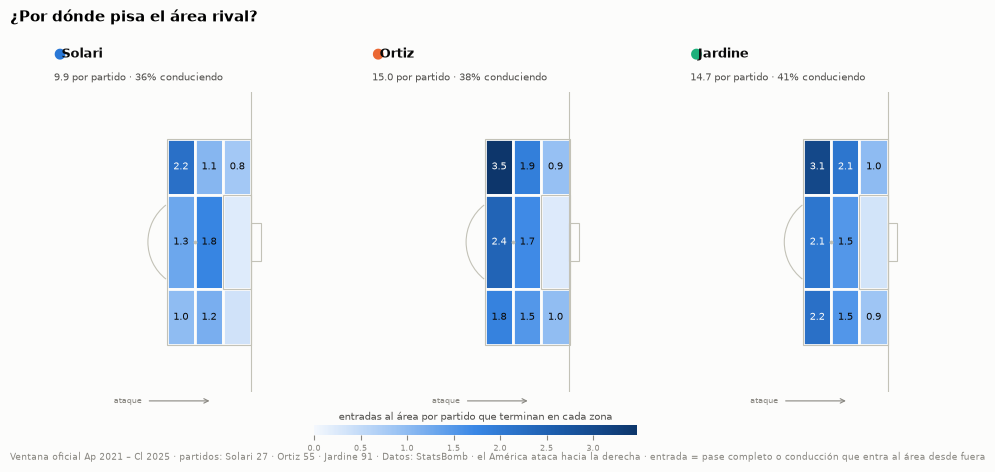

In [6]:
save(V.fig_lanes(prog, ents, scope, "¿Por dónde progresa el América?"), "progresion_carriles")
save(V.fig_box_entries(box_grid, ents, scope, "¿Por dónde pisa el área rival?"), "entradas_area")

In [7]:
pp = prog[prog.action == "Pase progresivo"].set_index(["coach", "lane"]).share * 100
f3 = ents[ents.entrada == "Último tercio"].groupby(["coach", "lane"]).por_partido.sum()
bx = ents[ents.entrada == "Área"].groupby("coach").por_partido.sum()
bxc = ents[(ents.entrada == "Área") & (ents.method == "Conducción")].groupby("coach").por_partido.sum() / bx * 100
finding("3.2b Progresión", "¿Por dónde progresa el América?",
    f"Jardine progresa por dentro y entra por fuera. El {pp['Jardine', 'Central']:.0f} % de sus pases progresivos termina en el "
    f"carril central, pero al último tercio llega sobre todo por las bandas: {f3['Jardine', 'Izquierdo']:.1f} entradas por "
    f"partido por la izquierda y {f3['Jardine', 'Derecho']:.1f} por la derecha, frente a {f3['Jardine', 'Central']:.1f} por el centro. "
    f"Pisa el área {bx['Jardine']:.1f} veces por partido, como Ortiz ({bx['Ortiz']:.1f}) y {(bx['Jardine'] / bx['Solari'] - 1) * 100:.0f} % "
    f"más que Solari ({bx['Solari']:.1f}); {bxc['Jardine']:.0f} % de esas entradas son conduciendo "
    f"(Ortiz {bxc['Ortiz']:.0f} %, Solari {bxc['Solari']:.0f} %).",
    ["progresion_carriles.png", "entradas_area.png"])

**¿Por dónde progresa el América?**

**Hallazgo.** Jardine progresa por dentro y entra por fuera. El 42 % de sus pases progresivos termina en el carril central, pero al último tercio llega sobre todo por las bandas: 21.1 entradas por partido por la izquierda y 17.9 por la derecha, frente a 9.3 por el centro. Pisa el área 14.7 veces por partido, como Ortiz (15.0) y 48 % más que Solari (9.9); 41 % de esas entradas son conduciendo (Ortiz 38 %, Solari 36 %).

### c) ¿Cómo genera ocasiones?

Tiros **sin penales**. **Origen** (definiciones del marco, las mismas de `xg_share_*` en `src/features.py`):
*balón parado* = la posesión la abre el saque del propio equipo en un córner o un tiro libre (o en un saque de banda en el
último tercio), sea cual sea la jugada que siga; la posesión que solo hereda la etiqueta de StatsBomb (p. ej., un
contragolpe tras atrapar un córner rival) no es balón parado, y si llega rápido es transición; *transición* = posesión que nace de un robo y llega al último tercio o al tiro en ≤ 15 s; *juego
posicional* = todo lo demás. **Jugada previa al tiro**: tiro libre directo → servicio a balón parado → pase atrás al área
(bandera de StatsBomb o pase raso desde la línea del área hacia atrás, a la zona de peligro) → centro → filtrado → otro pase
→ jugada individual (sin pase clave, tras regate o conducción propia ≥ 5 yd) → rebote o balón suelto.

In [8]:
sh = S.shots(ev, poss)                              # en memoria
tot = S.shot_totals(sh, scope)
org = S.chance_summary(sh, scope, "origin")
ast = S.chance_summary(sh, scope, "assist")
display(tot)
display(org.pivot(index="origin", columns="coach", values=["pct_xg", "xg_por_partido", "xg_por_tiro"]).round(2))
display(ast.pivot(index="assist", columns="coach", values=["pct_xg", "xg_por_tiro"]).reindex(S.ASSISTS).round(2))
for df, name in [(tot, "ocasiones_total"), (org, "ocasiones_origen"), (ast, "ocasiones_pase_previo"),
                 (S.shot_grid(sh), "tiros_rejilla")]:
    S.save_story(df, name)

,coach,tiros,np_xg,goles,pct_tiros_en_area,tiros_por_partido,np_xg_por_partido,xg_por_tiro
0,Solari,335,26.21,26,60.00,12.41,0.97,0.08
1,Ortiz,877,86.30,102,57.58,15.95,1.57,0.10
2,Jardine,1197,137.87,147,65.08,13.15,1.52,0.12


pct_xg              xg_por_partido              xg_por_tiro             
coach            Jardine Ortiz Solari        Jardine Ortiz Solari     Jardine Ortiz Solari
origin                                                                                    
Balón parado       36.82 33.12  43.13           0.56  0.52   0.42        0.11  0.09   0.07
Juego posicional   25.57 31.56  22.56           0.39  0.50   0.22        0.12  0.12   0.09
Transición         37.61 35.33  34.31           0.57  0.55   0.33        0.12  0.10   0.08

pct_xg              xg_por_tiro             
coach                   Jardine Ortiz Solari     Jardine Ortiz Solari
assist                                                               
Centro                    16.68 15.81  28.22        0.17  0.12   0.12
Pase atrás al área        14.78 10.37   8.18        0.14  0.13   0.08
Filtrado                   8.29  8.83   3.13        0.21  0.26   0.16
Otro pase                 28.06 33.38  24.55        0.08  0.08   0.06
Servicio a balón parado    6.81  9.31  13.23        0.09  0.09   0.08
Tiro libre directo         1.15  1.90   2.11        0.04  0.03   0.03
Jugada individual          2.74  5.01   4.38        0.07  0.09   0.06
Rebote o balón suelto     21.48 15.39  16.20        0.16  0.12   0.09

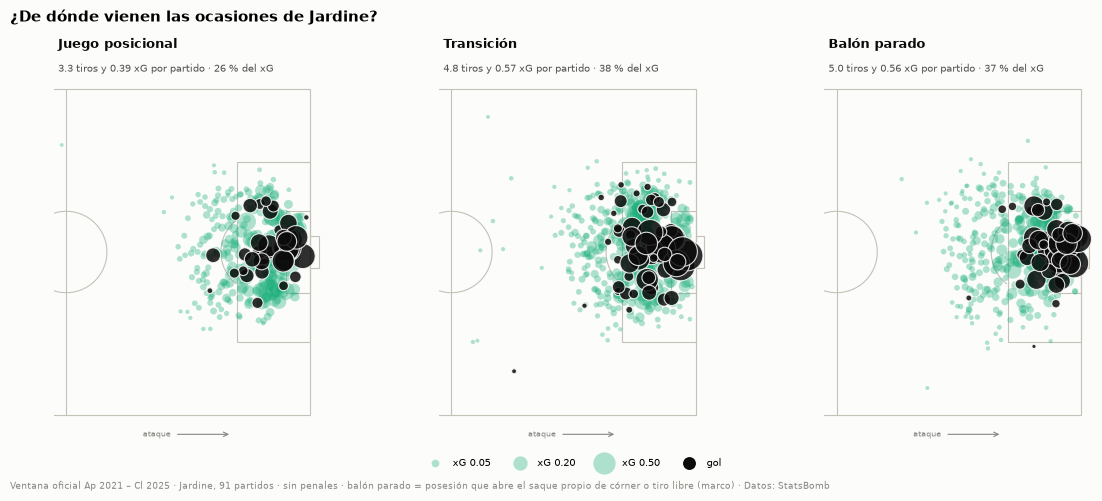

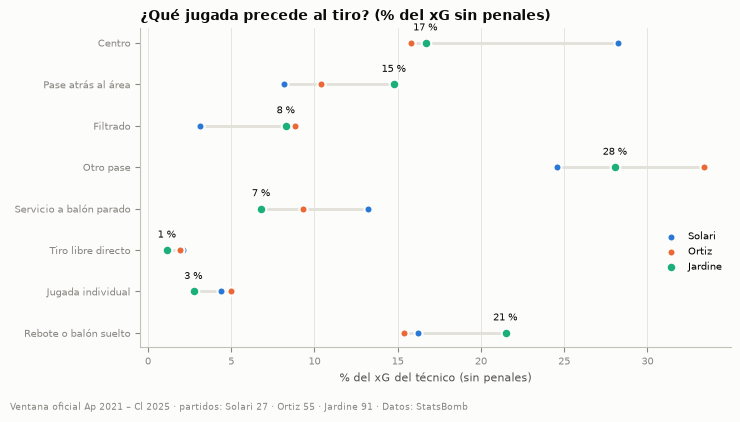

In [9]:
save(V.fig_shot_map(sh, org, scope, "¿De dónde vienen las ocasiones de Jardine?"), "tiros_origen")
save(V.fig_assists(ast, scope, "¿Qué jugada precede al tiro? (% del xG sin penales)", S.ASSISTS), "pase_previo")

In [10]:
t = tot.set_index("coach")
o = org.set_index(["coach", "origin"]).pct_xg
a = ast.pivot(index="assist", columns="coach", values="pct_xg").fillna(0)
finding("3.2c Ocasiones", "¿Cómo genera ocasiones el América?",
    f"Jardine no tira más, tira mejor: {t.loc['Jardine', 'tiros_por_partido']:.1f} tiros y "
    f"{t.loc['Jardine', 'np_xg_por_partido']:.2f} xG por partido sin penales (Ortiz {t.loc['Ortiz', 'tiros_por_partido']:.1f} tiros y "
    f"{t.loc['Ortiz', 'np_xg_por_partido']:.2f} xG), con {t.loc['Jardine', 'xg_por_tiro']:.2f} xG por tiro frente a "
    f"{t.loc['Ortiz', 'xg_por_tiro']:.2f} de Ortiz y {t.loc['Solari', 'xg_por_tiro']:.2f} de Solari, y "
    f"{t.loc['Jardine', 'pct_tiros_en_area']:.0f} % de sus tiros dentro del área. De su xG, "
    f"{o['Jardine', 'Juego posicional']:.0f} % nace del juego posicional, {o['Jardine', 'Transición']:.0f} % de transiciones y "
    f"{o['Jardine', 'Balón parado']:.0f} % de balón parado. Su jugada distintiva es el pase atrás al área: "
    f"{a.loc['Pase atrás al área', 'Jardine']:.0f} % del xG (Ortiz {a.loc['Pase atrás al área', 'Ortiz']:.0f} %, Solari "
    f"{a.loc['Pase atrás al área', 'Solari']:.0f} %); el centro pesa menos que con Solari "
    f"({a.loc['Centro', 'Jardine']:.0f} % frente a {a.loc['Centro', 'Solari']:.0f} %).",
    ["tiros_origen.png", "pase_previo.png"])

**¿Cómo genera ocasiones el América?**

**Hallazgo.** Jardine no tira más, tira mejor: 13.2 tiros y 1.52 xG por partido sin penales (Ortiz 15.9 tiros y 1.57 xG), con 0.12 xG por tiro frente a 0.10 de Ortiz y 0.08 de Solari, y 65 % de sus tiros dentro del área. De su xG, 26 % nace del juego posicional, 38 % de transiciones y 37 % de balón parado. Su jugada distintiva es el pase atrás al área: 15 % del xG (Ortiz 10 %, Solari 8 %); el centro pesa menos que con Solari (17 % frente a 28 %).

### d) ¿Quién conecta con quién?

**El 11 más usado**: el sistema más frecuente de Jardine en la ventana y, en cada puesto, el jugador que más veces lo
ocupó de titular. La red usa solo los partidos con ese sistema, cada jugador en los partidos en que fue titular en su
puesto, y los pases completos de juego abierto **hasta el primer cambio** (para que la foto sea la de ese 11). Nodo =
posición media de sus pases y recepciones; línea = pases entre la pareja por partido que jugaron juntos.

In [11]:
lu = S.starting_lineups(ev)
lj = lu[lu.coach == S.PROTAGONIST]
xi = S.most_used_xi(lj)
nodes, edges = S.pass_network(ev, lj, xi, names=S.player_short_names())
names = nodes.set_index("player_id").nombre
edges = edges.assign(jugador_a=edges.a.map(names), jugador_b=edges.b.map(names))
display(lj.drop_duplicates("match_id").formation.value_counts().head(5).to_frame("partidos"))
display(xi.assign(nombre=xi.player_id.map(names))[["position", "nombre", "titularidades"]])
display(nodes.sort_values("pases_por_partido", ascending=False)[["nombre", "position", "x_media", "y_media", "pases_por_partido", "partidos"]])
display(edges.sort_values("pases_por_partido", ascending=False).head(8)[["jugador_a", "jugador_b", "pases_por_partido", "partidos_juntos"]])
for df, name in [(xi, "red_xi"), (nodes, "red_nodos"), (edges, "red_aristas")]:
    S.save_story(df, name, muestra=f"ventana · {S.PROTAGONIST}")

,partidos
formation,
4231,41
442,23
433,7
343,7
4141,5


,position,nombre,titularidades
0,Goalkeeper,Luis Malagón,35
1,Center Attacking Midfield,Diego Valdés,26
2,Center Forward,Henry Martín,25
3,Right Wing,Alejandro Zendejas,23
4,Left Defensive Midfield,Álvaro Fidalgo,23
5,Right Back,Kevin Álvarez,21
6,Right Defensive Midfield,Jonathan dos Santos,20
7,Left Back,Cristian Calderón,20
8,Right Center Back,Igor Lichnovsky,15
9,Left Center Back,Ramón Juárez,15


,nombre,position,x_media,y_media,pases_por_partido,partidos
10,Álvaro Fidalgo,Left Defensive Midfield,62.30,29.14,28.48,23
0,Jonathan dos Santos,Right Defensive Midfield,57.85,43.65,27.10,20
1,Igor Lichnovsky,Right Center Back,42.35,57.18,14.73,15
9,Ramón Juárez,Left Center Back,36.48,27.43,13.40,15
5,Alejandro Zendejas,Right Wing,76.73,56.71,12.91,23
3,Diego Valdés,Center Attacking Midfield,74.78,37.01,11.38,26
2,Cristian Calderón,Left Back,60.35,11.16,10.55,20
6,Kevin Álvarez,Right Back,70.70,68.61,10.33,21
7,Brian Rodríguez,Left Wing,79.43,12.10,7.00,14
4,Henry Martín,Center Forward,78.57,38.88,5.52,25


,jugador_a,jugador_b,pases_por_partido,partidos_juntos
9,Jonathan dos Santos,Álvaro Fidalgo,21.11,19
50,Brian Rodríguez,Álvaro Fidalgo,15.50,4
25,Cristian Calderón,Álvaro Fidalgo,12.18,11
14,Igor Lichnovsky,Kevin Álvarez,10.40,5
16,Igor Lichnovsky,Ramón Juárez,10.11,9
4,Jonathan dos Santos,Alejandro Zendejas,10.07,14
39,Alejandro Zendejas,Kevin Álvarez,9.23,13
0,Jonathan dos Santos,Igor Lichnovsky,9.20,10


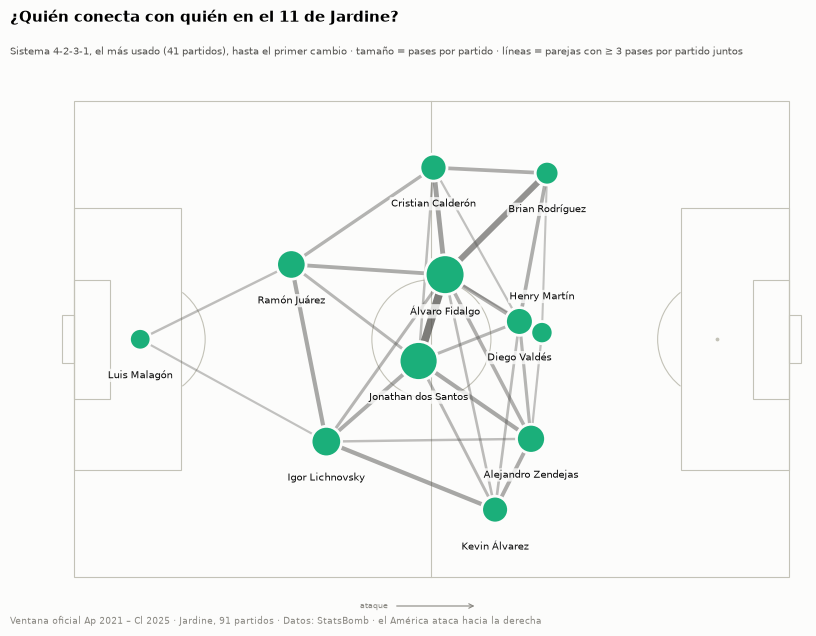

In [12]:
save(V.fig_pass_network(nodes, edges, xi, "¿Quién conecta con quién en el 11 de Jardine?",
                        f"Ventana oficial Ap 2021 – Cl 2025 · Jardine, {int((scope.coach == 'Jardine').sum())} partidos · "
                        "Datos: StatsBomb · el América ataca hacia la derecha"),
     "red_pases")

In [13]:
nd = nodes.sort_values("pases_por_partido", ascending=False)
e = edges[edges.partidos_juntos >= 5].sort_values("pases_por_partido", ascending=False)
top3 = "; ".join(f"{r.jugador_a}–{r.jugador_b} ({r.pases_por_partido:.0f})" for r in e.head(3).itertuples())
left = nodes[nodes.y_media < 40].pases_por_partido.sum() / nodes.pases_por_partido.sum() * 100
finding("3.2d Red de pases", "¿Quién conecta con quién en el 11 de Jardine?",
    f"En el {'-'.join(xi.formation.iat[0])} más usado ({xi.partidos_sistema.iat[0]} de {int((scope.coach == 'Jardine').sum())} partidos), "
    f"el balón pasa por el doble pivote: {nd.nombre.iat[0]} ({nd.pases_por_partido.iat[0]:.0f} pases por partido) y "
    f"{nd.nombre.iat[1]} ({nd.pases_por_partido.iat[1]:.0f}) son los que más pases dan. Las conexiones más usadas "
    f"(pases por partido juntos) son {top3}. El juego se carga a la izquierda: los jugadores de ese lado "
    f"dan {left:.0f} % de los pases del 11.",
    ["red_pases.png"])

**¿Quién conecta con quién en el 11 de Jardine?**

**Hallazgo.** En el 4-2-3-1 más usado (41 de 91 partidos), el balón pasa por el doble pivote: Álvaro Fidalgo (28 pases por partido) y Jonathan dos Santos (27) son los que más pases dan. Las conexiones más usadas (pases por partido juntos) son Jonathan dos Santos–Álvaro Fidalgo (21); Cristian Calderón–Álvaro Fidalgo (12); Igor Lichnovsky–Kevin Álvarez (10). El juego se carga a la izquierda: los jugadores de ese lado dan 56 % de los pases del 11.

## 3.3 Sin balón

### a) ¿Dónde recupera el balón?

**Recuperación** (marco: `regain`) = posesión propia que nace de un robo, una intercepción, un duelo ganado o un
bloqueo. Se ubica donde empieza esa posesión. *Campo rival* = x ≥ 60.

,coach,recuperaciones,altura_media_x,pct_campo_rival,pct_ultimo_tercio,pct_a_transicion,pct_a_tiro,por_partido,por_100_pos_rivales
0,Solari,1376,42.66,23.98,8.28,36.92,9.38,50.96,47.14
1,Ortiz,3009,42.13,24.66,7.94,39.35,12.26,54.71,51.54
2,Jardine,4717,41.76,23.77,8.10,39.75,10.88,51.84,50.11


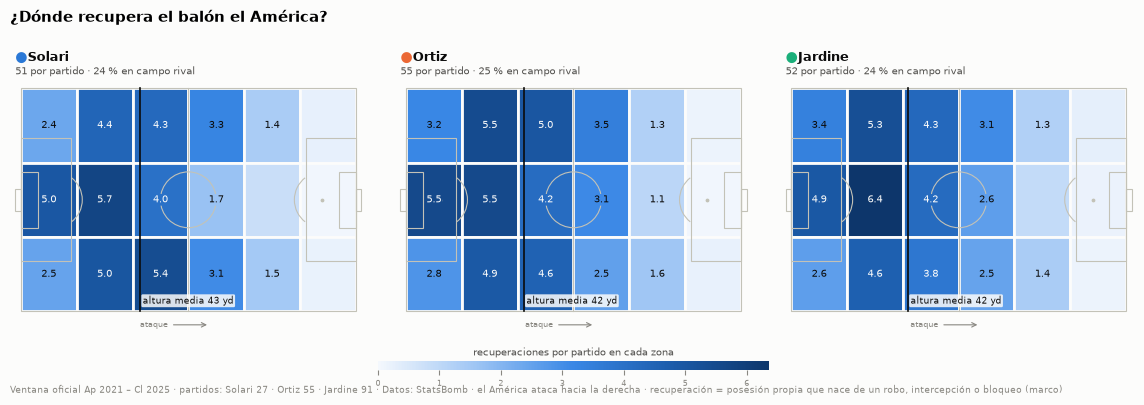

In [14]:
rec = S.recoveries(poss)                            # en memoria
rsum = S.recovery_summary(rec, poss, scope)
rgrid = S.grid_per_match(S.zone_grid(rec, "x", "y", ["coach"]), scope)
display(rsum)
S.save_story(rsum, "recuperaciones"); S.save_story(rgrid, "recuperaciones_zonas")
save(V.fig_recoveries(rgrid, rsum, scope, "¿Dónde recupera el balón el América?"), "recuperaciones")

In [15]:
rm = rsum.set_index("coach")
best = rgrid[rgrid.coach == "Jardine"].sort_values("por_partido").iloc[-1]
finding("3.3a Recuperación", "¿Dónde recupera el balón el América?",
    f"Jardine no roba más arriba que sus antecesores: recupera {rm.loc['Jardine', 'por_partido']:.0f} balones por partido a una "
    f"altura media de {rm.loc['Jardine', 'altura_media_x']:.0f} yd de su portería (Solari {rm.loc['Solari', 'altura_media_x']:.0f}, "
    f"Ortiz {rm.loc['Ortiz', 'altura_media_x']:.0f}) y {rm.loc['Jardine', 'pct_campo_rival']:.0f} % en campo rival "
    f"(Solari {rm.loc['Solari', 'pct_campo_rival']:.0f} %, Ortiz {rm.loc['Ortiz', 'pct_campo_rival']:.0f} %). Su zona de robo es "
    f"el centro de su propio campo, justo delante del área ({best.por_partido:.1f} recuperaciones por partido entre las "
    f"{best.x0:.0f} y las {best.x1:.0f} yd), y {rm.loc['Jardine', 'pct_a_transicion']:.0f} % de lo que recupera se convierte en "
    f"transición (Solari {rm.loc['Solari', 'pct_a_transicion']:.0f} %, Ortiz {rm.loc['Ortiz', 'pct_a_transicion']:.0f} %).",
    ["recuperaciones.png"])

**¿Dónde recupera el balón el América?**

**Hallazgo.** Jardine no roba más arriba que sus antecesores: recupera 52 balones por partido a una altura media de 42 yd de su portería (Solari 43, Ortiz 42) y 24 % en campo rival (Solari 24 %, Ortiz 25 %). Su zona de robo es el centro de su propio campo, justo delante del área (6.4 recuperaciones por partido entre las 20 y las 40 yd), y 40 % de lo que recupera se convierte en transición (Solari 37 %, Ortiz 39 %).

### b) ¿Presiona más o menos que la liga?

Dos fuentes, cada una para lo suyo:
- **Frente a Solari y Ortiz**, con las métricas del marco calculadas con eventos (`match_features`: PPDA, % de acciones
  defensivas en campo rival, contrapresión por pérdida, % de pérdidas recuperadas en ≤ 5 s).
- **Frente a la liga**, con las métricas de StatsBomb que existen para todos los equipos (`fct_team_match_league`), la
  misma fuente para el América y para los 70 técnicos-club con 15 partidos o más en la ventana.

**Ajuste por época.** La liga entera se mueve en la ventana (el PPDA medio pasa de ~8 en 2021 a ~12 en 2024 y las
recuperaciones por contrapresión se duplican desde el Apertura 2024), así que cada partido se compara con la **media de
la liga en el mismo torneo**. Sin ese ajuste, un técnico reciente como Jardine parecería presionar menos solo por la época.

In [16]:
press = S.pressing_by_coach(mf, scope)
bench = S.league_benchmark(tml)                     # diferencia con la liga del mismo torneo
bench_raw = S.league_benchmark(tml, relative=False) # valores crudos (para citar el número absoluto)
ranks = pd.DataFrame([{"metrica": c, "etiqueta": lab, "lectura": better, "coach": co,
                       **S.league_rank(bench, c, co), "valor_crudo": bench_raw.loc[bench_raw.coach == co, c].iat[0]}
                      for c, (lab, better) in S.LEAGUE_METRICS.items() for co in S.COACHES])
display(press[["coach"] + S.PRESS_METRICS])
display(ranks.pivot(index="etiqueta", columns="coach", values=["valor", "percentil"]).round(2))
S.save_story(press, "presion"); S.save_story(bench, "presion_liga"); S.save_story(ranks, "presion_liga_rank")

,coach,ppda,high_press_pct,def_action_x_mean,high_regains_per100opp,counterpress_per_loss,quick_regain_pct
0,Solari,10.23,43.40,54.80,11.01,0.95,13.56
1,Ortiz,11.44,41.60,53.65,12.50,0.95,12.20
2,Jardine,13.83,39.94,52.51,11.76,0.90,13.85


valor              percentil             
coach                                              Jardine Ortiz Solari   Jardine Ortiz Solari
etiqueta                                                                                      
% de presiones en campo rival                         0.02  0.03   0.06     70.71 87.86  97.86
Contrapresiones por partido                          -2.26 -0.10  -3.41     17.86 60.71   9.29
Distancia media de las acciones defensivas a su...    1.10  1.75   2.11     79.29 90.71  93.57
PPDA (pases rivales por acción defensiva)             1.90 -0.55   0.39     85.00 39.29  66.43
Recuperaciones por contrapresión por partido          0.21  0.11  -1.25     73.57 67.86  17.86
Tiros de contraataque concedidos por partido         -0.24 -0.33  -0.48     19.29 10.71   5.00
Tiros de contraataque por partido                     0.08  0.04  -0.52     69.29 60.71   6.43

'C:\\Users\\pauli\\Documents\\ISAC\\ISAC-Hackathon-America\\data\\gold\\analysis\\story_presion_liga_rank.parquet'

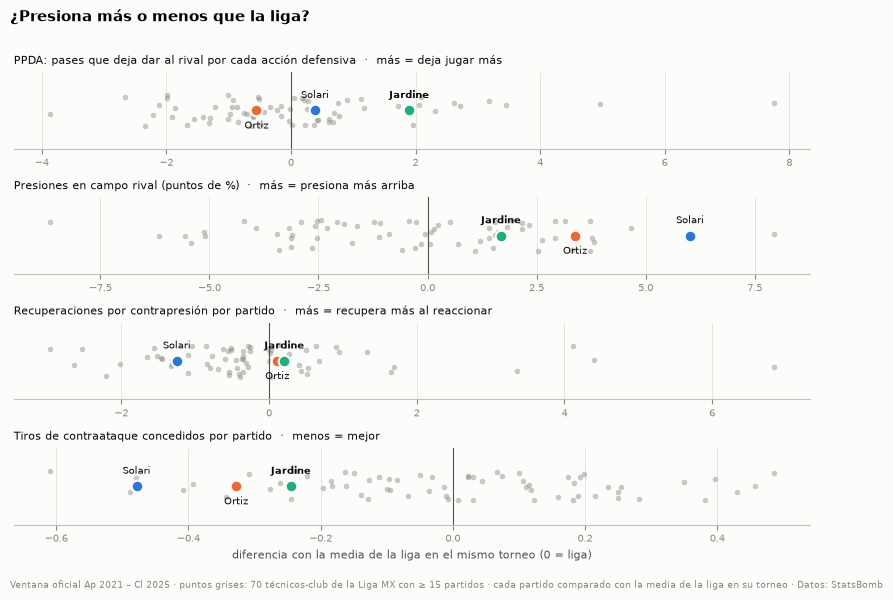

In [17]:
PRESS_FIG = {
    "team_match_ppda": ("PPDA: pases que deja dar al rival por cada acción defensiva", "más = deja jugar más", 1),
    "team_match_fhalf_pressures_ratio": ("Presiones en campo rival (puntos de %)", "más = presiona más arriba", 100),
    "team_match_counterpressure_regains": ("Recuperaciones por contrapresión por partido", "más = recupera más al reaccionar", 1),
    "team_match_counter_attacking_shots_conceded": ("Tiros de contraataque concedidos por partido", "menos = mejor", 1),
}
save(V.fig_press_league(bench, PRESS_FIG, "¿Presiona más o menos que la liga?",
                        "Ventana oficial Ap 2021 – Cl 2025 · puntos grises: 70 técnicos-club de la Liga MX con ≥ 15 partidos · "
                        "cada partido comparado con la media de la liga en su torneo · Datos: StatsBomb"),
     "presion_liga")

In [18]:
rk = ranks.set_index(["metrica", "coach"])
pp_ = rk.loc[("team_match_ppda", "Jardine")]
fh = rk.loc[("team_match_fhalf_pressures_ratio", "Jardine")]
cpr = rk.loc[("team_match_counterpressure_regains", "Jardine")]
cpn = rk.loc[("team_match_counterpressures", "Jardine")]
pm = press.set_index("coach")
finding("3.3b Presión", "¿Presiona más o menos que la liga?",
    f"Jardine no asfixia al rival: le deja dar {abs(pp_.valor):.1f} pases {'más' if pp_.valor > 0 else 'menos'} por cada intento de recuperación que la media de la "
    f"liga en el mismo torneo (PPDA; el {int(pp_.lugar)}.º más alto de {int(pp_.de)} técnicos), mientras Ortiz presionaba más que "
    f"la liga ({rk.loc[('team_match_ppda', 'Ortiz'), 'valor']:+.1f}). Con los eventos se ve igual: PPDA mediano de "
    f"{pm.loc['Jardine', 'ppda']:.1f} frente a {pm.loc['Ortiz', 'ppda']:.1f} de Ortiz y {pm.loc['Solari', 'ppda']:.1f} de Solari. "
    f"Pero cuando presiona, lo hace arriba: {fh.valor * 100:.1f} puntos más de sus presiones en campo rival que la liga "
    f"(más que {fh.percentil:.0f} de cada 100 técnicos), y aunque tras perder el balón contrapresiona menos que la liga "
    f"({abs(cpn.valor):.1f} veces menos por partido), recupera un poco más así ({cpr.valor:.1f} balones más por partido; "
    f"más que {cpr.percentil:.0f} de cada 100 técnicos).",
    ["presion_liga.png"])

**¿Presiona más o menos que la liga?**

**Hallazgo.** Jardine no asfixia al rival: le deja dar 1.9 pases más por cada intento de recuperación que la media de la liga en el mismo torneo (PPDA; el 11.º más alto de 70 técnicos), mientras Ortiz presionaba más que la liga (-0.6). Con los eventos se ve igual: PPDA mediano de 13.8 frente a 11.4 de Ortiz y 10.2 de Solari. Pero cuando presiona, lo hace arriba: 1.7 puntos más de sus presiones en campo rival que la liga (más que 71 de cada 100 técnicos), y aunque tras perder el balón contrapresiona menos que la liga (2.3 veces menos por partido), recupera un poco más así (0.2 balones más por partido; más que 74 de cada 100 técnicos).

### c) ¿Cómo le va en las transiciones?

**Transición ofensiva** (marco): posesión que nace de un robo y llega al último tercio o al tiro en ≤ 15 s (sin balón
parado). **Transición defensiva**: lo mismo, pero del rival. La velocidad es el tiempo (mediana, en segundos) desde el
robo hasta el último tercio o el tiro. En los mapas, todo en coordenadas del América: las transiciones del rival se ubican
**donde el América perdió el balón**. Además, la reacción inmediata tras perder: % de pérdidas recuperadas en ≤ 5 s.

,coach,transiciones,segundos_mediana,pct_tiro,xg,xg_por_transicion,pct_de_recuperaciones,por_partido,xg_por_partido,lado
0,Solari,508,6.00,20.47,8.99,0.02,36.92,18.81,0.33,A favor
1,Ortiz,1184,6.00,24.16,30.49,0.03,39.35,21.53,0.55,A favor
2,Jardine,1875,6.00,21.44,51.85,0.03,39.75,20.60,0.57,A favor
3,Solari,432,6.00,19.91,9.54,0.02,30.77,16.00,0.35,En contra
4,Ortiz,979,6.00,20.94,17.79,0.02,35.01,17.80,0.32,En contra
5,Jardine,1649,5.00,21.22,28.18,0.02,35.76,18.12,0.31,En contra


,coach,losses,quick_regains,pct_recuperado_5s,perdidas_por_partido
0,Solari,1277,195,15.27,47.30
1,Ortiz,2593,348,13.42,47.15
2,Jardine,4337,612,14.11,47.66


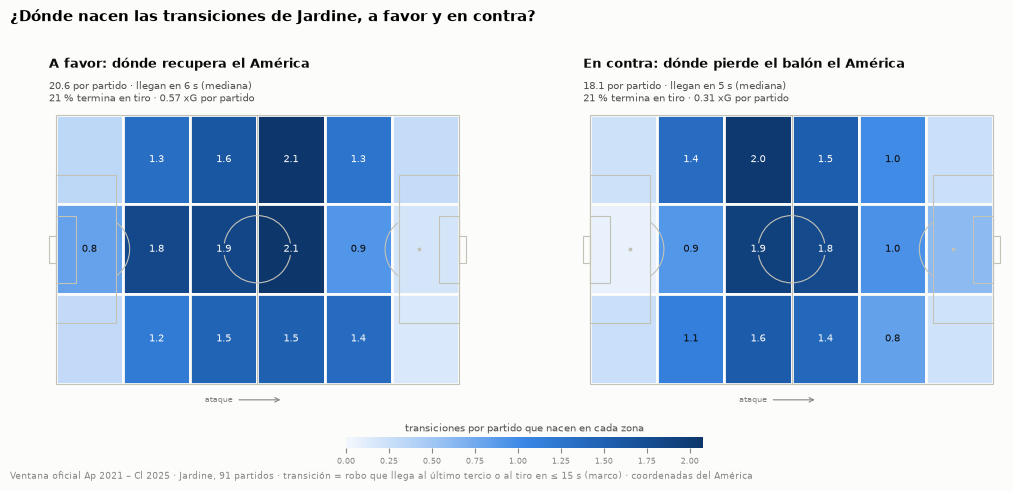

In [19]:
tr = S.transition_summary(poss, scope)
cp = S.counterpress_summary(poss, scope)
starts = S.transition_starts(poss)                  # en memoria
tgrid = S.grid_per_match(S.zone_grid(starts, "x", "y", ["coach", "lado"], ("xg",)), scope)
display(tr, cp)
for df, name in [(tr, "transiciones"), (cp, "contrapresion"), (tgrid, "transiciones_zonas")]:
    S.save_story(df, name)
save(V.fig_transitions(tgrid, tr, scope, "¿Dónde nacen las transiciones de Jardine, a favor y en contra?"), "transiciones")

In [20]:
t = tr.set_index(["coach", "lado"])
ratio = {c: t.loc[(c, "A favor"), "xg_por_partido"] / t.loc[(c, "En contra"), "xg_por_partido"] for c in S.COACHES}
ca = S.league_rank(bench, "team_match_counter_attacking_shots_conceded", "Jardine", higher_is_more=False)
ca_raw = rk.loc[("team_match_counter_attacking_shots_conceded", "Jardine"), "valor_crudo"]
fav, con = t.loc[("Jardine", "A favor")], t.loc[("Jardine", "En contra")]
finding("3.3c Transiciones", "¿Cómo le va al América en las transiciones?",
    f"Jardine gana el intercambio: {fav.por_partido:.1f} transiciones a favor por partido que valen {fav.xg_por_partido:.2f} xG, "
    f"frente a {con.por_partido:.1f} del rival que valen {con.xg_por_partido:.2f} xG: {ratio['Jardine']:.1f} veces más peligro a "
    f"favor que en contra (Ortiz {ratio['Ortiz']:.1f}, Solari {ratio['Solari']:.1f}). Las suyas llegan al último tercio en "
    f"unos {fav.segundos_mediana:.0f} s (las del rival, en {con.segundos_mediana:.0f} s). Frente a la liga concede pocos contragolpes: {ca_raw:.2f} tiros de contraataque por "
    f"partido, {-ca['valor']:.2f} menos que la media de su torneo ({ca['lugar']}.º que menos de {ca['de']} técnicos).",
    ["transiciones.png", "presion_liga.png"])

**¿Cómo le va al América en las transiciones?**

**Hallazgo.** Jardine gana el intercambio: 20.6 transiciones a favor por partido que valen 0.57 xG, frente a 18.1 del rival que valen 0.31 xG: 1.8 veces más peligro a favor que en contra (Ortiz 1.7, Solari 0.9). Las suyas llegan al último tercio en unos 6 s (las del rival, en 5 s). Frente a la liga concede pocos contragolpes: 0.89 tiros de contraataque por partido, 0.24 menos que la media de su torneo (14.º que menos de 70 técnicos).

## 3.4 360: ¿qué tan alto y qué tan junto defiende?

**Fuente.** StatsBomb 360: en cada evento, la posición de los jugadores **que se ven en la toma** y el polígono de lo
visible (`visible_area`). No es tracking: fuera de cuadro no hay nadie. Solo hay 360 de partidos del América, así que la
comparación es **entre técnicos** (no contra la liga).

**Definiciones** (umbrales en `ASSUMPTIONS` de `src/framework.py`):
- **Momento**: cada pase rival de juego abierto, fuera de posesiones de balón parado. Todo en coordenadas del América
  (su portería en x = 0).
- **Fase**, según dónde está el balón (umbrales de presión del marco): **bloque alto** (balón en campo rival, x ≥ 60),
  **medio** (40–60) y **bajo** (< 40, su tercio). **Tras pérdida**: los primeros 5 s de una posesión rival que nació de
  una del América (ventana de contrapresión del marco); el resto es **posesión rival**.
- **Última línea** = los 4 jugadores de campo visibles más retrasados (`shape_line_players`); **segunda línea** = los 4
  siguientes; **bloque** = esos 8 (`shape_block_players`). Largo = del más retrasado al 8.º; ancho = de banda a banda
  entre esos 8.
- **Frame útil**: al menos 8 jugadores de campo del América visibles (`shape_min_visible`) **y** la toma ve al menos 5 yd
  detrás del más retrasado (`shape_min_behind_yd`); si no, podría haber un defensor más atrás fuera de cuadro y la línea
  saldría más alta de lo que es.
- Cifras = mediana de los frames útiles; las diferencias entre técnicos se prueban con el **partido como unidad**
  (media de las medianas por partido, IC 90 % por remuestreo de partidos).

In [21]:
fr = S.load_story_frames(scope)                     # 360: SOLO en memoria
rp = S.rival_open_play_passes(ev, poss)
shape = S.defensive_shape(fr, rp); del fr
by_phase = S.shape_summary(shape[shape.situacion == "Posesión rival"], ["fase"])
by_sit = S.shape_summary(shape, ["situacion"])
cov = S.shape_summary(shape, [])[["coach", "pases_rivales", "pct_con_360", "frames_utiles", "pct_utiles"]]
FILTERS = {"Bloque medio": {"situacion": "Posesión rival", "fase": "Bloque medio"},
           "Bloque bajo": {"situacion": "Posesión rival", "fase": "Bloque bajo"},
           "Bloque alto": {"situacion": "Posesión rival", "fase": "Bloque alto"},
           "Tras pérdida": {"situacion": "Tras pérdida"}}
diffs = pd.DataFrame([{"comparacion": f"Jardine − {b}", "metrica": m, "filtro": lab,
                       **S.match_level_diff(shape, m, "Jardine", b, **flt)}
                      for b in ["Ortiz", "Solari"] for m in S.SHAPE_METRICS for lab, flt in FILTERS.items()])
show = ["coach", "pases_rivales", "pct_utiles"] + list(S.SHAPE_METRICS) + ["ball_x"]
display(cov, by_phase[["fase"] + show], by_sit[["situacion"] + show])
display(diffs.pivot_table(index=["metrica", "filtro"], columns="comparacion", values="diferencia").round(1))
for df, name in [(by_phase, "forma_fase"), (by_sit, "forma_situacion"), (cov, "forma_cobertura"),
                 (diffs, "forma_diferencias")]:
    S.save_story(df, name)

,coach,pases_rivales,pct_con_360,frames_utiles,pct_utiles
0,Jardine,26545,89.53,8591,32.36
1,Ortiz,14157,90.05,3967,28.02
2,Solari,6922,87.07,2205,31.85


,fase,coach,pases_rivales,pct_utiles,altura_linea,distancia_lineas,largo_bloque,ancho_bloque,distancia_balon_linea,ball_x
0,Bloque alto,Jardine,11247,16.46,47.75,14.00,23.40,44.00,21.95,68.20
1,Bloque bajo,Jardine,3938,57.67,19.68,8.97,15.30,37.00,9.68,31.60
2,Bloque medio,Jardine,5019,58.88,31.77,12.30,20.20,41.00,17.70,50.00
3,Bloque alto,Ortiz,5543,14.02,49.38,15.05,25.40,44.10,19.93,68.50
4,Bloque bajo,Ortiz,2241,40.87,19.90,10.40,18.10,37.10,9.26,31.25
5,Bloque medio,Ortiz,2470,55.14,33.70,13.38,22.60,41.80,16.24,50.05
6,Bloque alto,Solari,2900,17.03,47.16,12.81,21.30,43.95,20.84,67.10
7,Bloque bajo,Solari,956,55.13,19.85,8.80,14.70,37.60,9.28,31.50
8,Bloque medio,Solari,1167,61.78,33.25,11.50,18.40,41.80,16.95,50.70


,situacion,coach,pases_rivales,pct_utiles,altura_linea,distancia_lineas,largo_bloque,ancho_bloque,distancia_balon_linea,ball_x
0,Posesión rival,Jardine,20204,35.03,30.97,11.82,19.60,40.60,15.90,48.40
1,Tras pérdida,Jardine,6341,23.88,39.51,13.50,23.60,40.30,12.00,53.60
2,Posesión rival,Ortiz,10254,29.79,32.97,12.97,22.10,41.10,14.98,49.20
3,Tras pérdida,Ortiz,3903,23.37,44.77,14.10,24.70,40.00,10.62,58.80
4,Posesión rival,Solari,5023,34.68,32.67,10.90,18.05,41.30,15.76,50.20
5,Tras pérdida,Solari,1899,24.38,43.75,13.30,22.60,38.90,10.70,56.50


comparacion                         Jardine − Ortiz  Jardine − Solari
metrica               filtro                                         
altura_linea          Bloque alto             -1.60              0.30
                      Bloque bajo             -1.00             -0.30
                      Bloque medio            -1.70             -1.40
                      Tras pérdida            -6.10             -3.10
ancho_bloque          Bloque alto              0.30             -0.00
                      Bloque bajo              0.10             -1.30
                      Bloque medio            -0.40             -0.30
                      Tras pérdida            -0.10              0.60
distancia_balon_linea Bloque alto              1.80              0.80
                      Bloque bajo              0.00              0.80
                      Bloque medio             1.00              1.10
                      Tras pérdida             1.30              1.00
distancia_lineas      Bloque alto             -0.50              0.90
                      Bloque bajo             -1.10              0.50
                      Bloque medio            -1.00              0.60
                      Tras pérdida            -0.50              0.00
largo_bloque          Bloque alto             -0.90              1.80
                      Bloque bajo             -2.80              0.80
                      Bloque medio            -2.10              1.40
                      Tras pérdida            -0.90              0.80

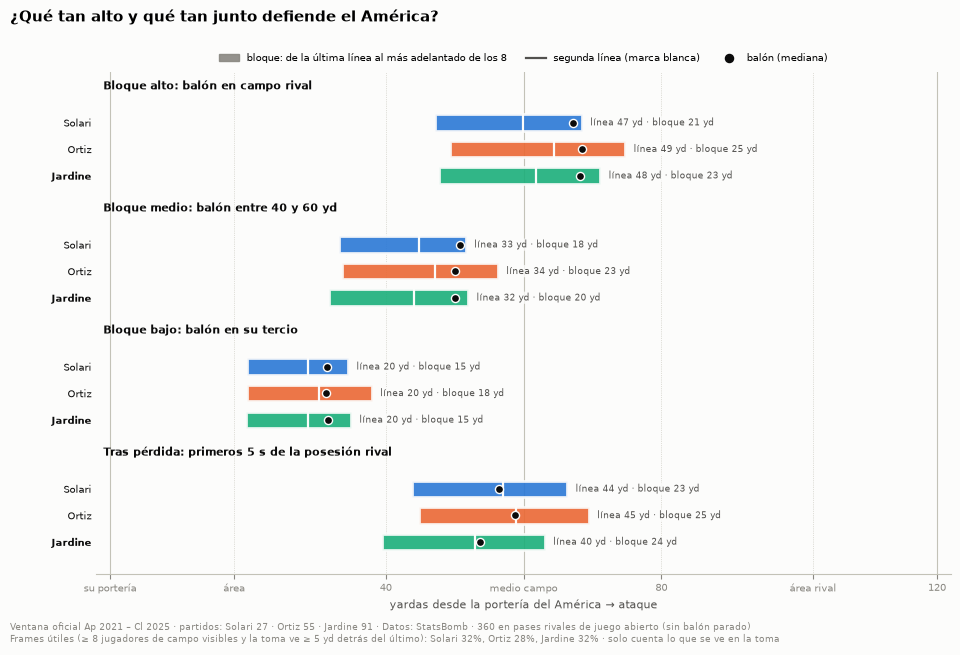

In [22]:
save(V.fig_block_shape(by_phase, by_sit, scope, "¿Qué tan alto y qué tan junto defiende el América?"), "forma_bloque")

In [23]:
ph = by_phase.set_index(["coach", "fase"])
st = by_sit.set_index(["coach", "situacion"])
dd = diffs.set_index(["comparacion", "metrica", "filtro"])
L = dd.loc[("Jardine − Ortiz", "largo_bloque", "Bloque medio")]
H_ = dd.loc[("Jardine − Ortiz", "altura_linea", "Bloque medio")]
m, b, tl = ("Jardine", "Bloque medio"), ("Jardine", "Bloque bajo"), ("Jardine", "Tras pérdida")
d_bl = {c: st.loc[(c, "Tras pérdida"), "distancia_balon_linea"] for c in S.COACHES}
same = abs(d_bl["Jardine"] - d_bl["Ortiz"]) < 2
cv = cov.set_index("coach")
alto_util = ph.xs("Bloque alto", level="fase").pct_utiles
finding("3.4 Forma defensiva (360)", "¿Qué tan alto y qué tan junto defiende el América?",
    f"Jardine defiende un poco más atrás y más junto que Ortiz. Con el balón entre las 40 y las 60 yd (bloque medio), su "
    f"última línea está a {ph.loc[m, 'altura_linea']:.0f} yd de su portería (Ortiz {ph.loc[('Ortiz', 'Bloque medio'), 'altura_linea']:.0f}, "
    f"Solari {ph.loc[('Solari', 'Bloque medio'), 'altura_linea']:.0f}; por partido, {H_.diferencia:+.1f} yd frente a Ortiz, IC 90 % "
    f"{H_.lo:+.1f} a {H_.hi:+.1f}) y su bloque mide {ph.loc[m, 'largo_bloque']:.0f} yd de largo, {abs(L.diferencia):.1f} yd menos que el de "
    f"Ortiz (IC 90 % {abs(L.hi):.1f} a {abs(L.lo):.1f}). Donde más se nota es atrás: en bloque bajo junta a sus 8 jugadores en "
    f"{ph.loc[b, 'largo_bloque']:.0f} yd (Ortiz {ph.loc[('Ortiz', 'Bloque bajo'), 'largo_bloque']:.0f}, Solari "
    f"{ph.loc[('Solari', 'Bloque bajo'), 'largo_bloque']:.0f}) con {ph.loc[b, 'distancia_lineas']:.0f} yd entre líneas. El ancho casi no "
    f"cambia ({ph.loc[m, 'ancho_bloque']:.0f} yd en bloque medio). Tras perder el balón su línea queda más atrás "
    f"({st.loc[tl, 'altura_linea']:.0f} yd frente a {st.loc[('Ortiz', 'Tras pérdida'), 'altura_linea']:.0f} de Ortiz), pero sobre todo porque "
    f"pierde el balón más atrás (a {st.loc[tl, 'ball_x']:.0f} yd frente a {st.loc[('Ortiz', 'Tras pérdida'), 'ball_x']:.0f}): la línea queda a "
    f"{d_bl['Jardine']:.0f} yd del balón (Ortiz {d_bl['Ortiz']:.0f}), " + ("casi lo mismo. " if same else "algo más lejos. ")
    + f"Encaja con su presión media (§3.3): no adelanta la defensa para asfixiar, la junta. Límite: solo cuenta lo que se ve en "
    f"la toma; {cv.loc['Jardine', 'pct_utiles']:.0f} % de los pases rivales de Jardine dan un frame útil, y solo "
    f"{alto_util['Jardine']:.0f} % en bloque alto (la cámara sigue al balón, lejos de la defensa).",
    ["forma_bloque.png"])

**¿Qué tan alto y qué tan junto defiende el América?**

**Hallazgo.** Jardine defiende un poco más atrás y más junto que Ortiz. Con el balón entre las 40 y las 60 yd (bloque medio), su última línea está a 32 yd de su portería (Ortiz 34, Solari 33; por partido, -1.7 yd frente a Ortiz, IC 90 % -2.5 a -0.8) y su bloque mide 20 yd de largo, 2.1 yd menos que el de Ortiz (IC 90 % 1.5 a 2.7). Donde más se nota es atrás: en bloque bajo junta a sus 8 jugadores en 15 yd (Ortiz 18, Solari 15) con 9 yd entre líneas. El ancho casi no cambia (41 yd en bloque medio). Tras perder el balón su línea queda más atrás (40 yd frente a 45 de Ortiz), pero sobre todo porque pierde el balón más atrás (a 54 yd frente a 59): la línea queda a 12 yd del balón (Ortiz 11), casi lo mismo. Encaja con su presión media (§3.3): no adelanta la defensa para asfixiar, la junta. Límite: solo cuenta lo que se ve en la toma; 32 % de los pases rivales de Jardine dan un frame útil, y solo 16 % en bloque alto (la cámara sigue al balón, lejos de la defensa).

## 3.8 Balón parado: ¿cómo ataca y cómo defiende las jugadas a balón parado?

Por partido el balón parado es ruido, así que se mira **agregado de toda la era** (ventana oficial).

**Jugada a balón parado** (`story.set_piece_plays`, sobre `fct_set_piece`): la posesión la abre el saque del equipo que
la tiene (su primer evento es el córner, el tiro libre o el saque de banda, o un tiro libre directo). Se descartan las
posesiones que solo heredan la etiqueta (p. ej., el portero rival atrapa el córner y su posesión sigue marcada "From
Corner"). **Córners**, todos; **tiros libres** y **saques de banda**, solo desde el último tercio de quien saca
(`set_piece_free_kick_x_min`, `set_piece_throw_in_x_min`).
- **Zona de entrega**: la del marco (`framework.set_piece_target_zone`): corto (< 15 yd), área chica, zona de penal,
  costados del área o fuera. **Zona de remate**: las mismas zonas con la ubicación del tiro; en córners, además, primer o
  segundo palo (mitad del ancho del lado del saque).
- **xG** sin penales, de toda la jugada. **Remate directo** = el tiro que asiste el propio saque o el tiro libre directo;
  lo demás es segunda jugada.
- **Dos cifras de "xG a balón parado"**, para no mezclarlas: la del marco (§3.2: toda la posesión que abre el saque propio de un
  córner o un tiro libre **en cualquier zona**, o de un saque de banda en el último tercio) y la de esta sección (jugadas del
  último tercio y córners, toda la jugada o solo el remate directo).
- **En contra, con 360 en el momento del saque** (córners rivales no jugados en corto): cuántos defensores del América
  hay en el área y en el área chica, y cuántos están **pegados** a un atacante (≤ 2 yd, `set_piece_marking_yd`). Para
  saber si eso es marcaje o casualidad, se compara con el **azar**: el mismo cálculo con los atacantes de otro córner
  del mismo técnico. Un córner cuenta si la toma ve ≥ 90 % del área y toda el área chica (`set_piece_min_box_visible`).
- **Frente a la liga**: métricas de balón parado de StatsBomb para todos los equipos, contra la media de la liga en el
  mismo torneo (como en §3.3), y el eje "Balón parado" del ADN (notebook 04).

In [24]:
sp_all = S.load_set_pieces(scope)
plays = S.set_piece_plays(sp_all, ev)                   # en memoria
sps = S.set_piece_shots(ev, plays)                      # en memoria
bp = S.set_piece_summary(plays, sps, scope)
deliv = S.delivery_summary(plays)
szone = S.shot_zone_summary(sps)
xgdef = S.set_piece_xg_share(sh, sps)                   # sh = tiros sin penales de §3.2c
bgrid = S.zone_grid(sps.assign(goles=sps.goal.astype(int)), "x", "y", ["coach", "lado"], ("xg", "goles"),
                    list(range(60, 121, 4)), list(range(0, 81, 4)))
bgrid = bgrid[bgrid.n > 0].reset_index(drop=True)
display(bp.pivot_table(index=["lado", "kind"], columns="coach", values=["por_partido", "pct_tiro", "xg_por_jugada",
                                                                          "pct_xg_directo", "goles"])[
    [(m, c) for m in ["por_partido", "pct_tiro", "xg_por_jugada", "pct_xg_directo", "goles"] for c in S.COACHES]].round(3))
display((deliv[deliv.kind == "Córner"].pivot_table(index=["lado", "dimension", "valor"], columns="coach", values="share")
         * 100).round(0)[S.COACHES])
display(szone.pivot_table(index=["lado", "dimension", "valor"], columns="coach", values="pct_xg").round(0)[S.COACHES])
display(xgdef.round(1))
for df, name in [(bp, "bp_resumen"), (deliv, "bp_entregas"), (szone, "bp_zonas_remate"), (xgdef, "bp_xg_definiciones"),
                 (bgrid, "bp_tiros_rejilla")]:
    S.save_story(df, name)

por_partido               pct_tiro               xg_por_jugada               pct_xg_directo                goles              
coach                         Solari Ortiz Jardine   Solari Ortiz Jardine        Solari Ortiz Jardine         Solari Ortiz Jardine Solari Ortiz Jardine
lado      kind                                                                                                                                         
A favor   Córner                4.74  5.76    5.00    42.19 36.59   35.60          0.04  0.03    0.04          47.95 44.66   34.84   2.00  7.00   16.00
          Saque de banda        8.63  7.82    7.08     9.44 12.09   10.71          0.01  0.01    0.01           0.77  3.81    2.03   1.00  7.00   11.00
          Tiro libre            3.37  2.94    2.53    43.96 50.62   39.56          0.03  0.04    0.04          62.10 57.06   41.57   1.00 12.00    8.00
          Total                16.74 16.53   14.60    25.66 27.50   24.23          0.02  0.02    0.03          44.00 40.53   28.35   4.00 26.00   35.00
En contra Córner                3.70  3.91    4.83    38.00 34.42   39.77          0.03  0.04    0.04          59.33 46.98   41.30   4.00  9.00   10.00
          Saque de banda        7.11  6.75    6.65    11.46 12.40   12.40          0.01  0.01    0.01           9.54  2.35    3.50   2.00  0.00    1.00
          Tiro libre            1.85  2.07    1.59    40.00 42.98   57.24          0.04  0.03    0.04          42.52 45.13   67.91   2.00  5.00    5.00
          Total                12.67 12.73   13.08    23.39 24.14   27.98          0.02  0.02    0.02          42.24 37.45   37.77   8.00 14.00   16.00

coach                                      Solari  Ortiz  Jardine
lado      dimension       valor                                  
A favor   Tipo de envío   Abierto           45.00  35.00    23.00
                          Cerrado           40.00  45.00    38.00
                          Corto              9.00  13.00    25.00
                          Otro               6.00   7.00    15.00
          Zona de entrega Corto              9.00  13.00    25.00
                          Fuera del área     9.00   5.00    16.00
                          Zona de penal     65.00  47.00    38.00
                          Área (costados)    4.00   8.00     5.00
                          Área chica        13.00  27.00    16.00
En contra Tipo de envío   Abierto           30.00  40.00    48.00
                          Cerrado           35.00  38.00    38.00
                          Corto             18.00  12.00     8.00
                          Otro              17.00  11.00     7.00
          Zona de entrega Corto             20.00  12.00     8.00
                          Fuera del área    14.00  10.00     7.00
                          Zona de penal     43.00  47.00    53.00
                          Área (costados)    8.00   7.00     8.00
                          Área chica        15.00  25.00    24.00

coach                                Solari  Ortiz  Jardine
lado      dimension valor                                  
A favor   palo      Primer palo       31.00  64.00    50.00
                    Segundo palo      69.00  36.00    50.00
          zona      Fuera del área    16.00  14.00    10.00
                    Zona de penal     60.00  52.00    47.00
                    Área (costados)    3.00   6.00     7.00
                    Área chica        21.00  28.00    35.00
En contra palo      Primer palo       58.00  58.00    53.00
                    Segundo palo      42.00  42.00    47.00
          zona      Fuera del área    11.00  14.00    13.00
                    Zona de penal     61.00  38.00    52.00
                    Área (costados)    6.00   7.00     7.00
                    Área chica        21.00  41.00    29.00

,coach,xg_total,pct_marco,pct_jugadas,pct_directo
0,Solari,26.20,43.10,32.50,14.30
1,Ortiz,86.30,33.10,25.40,10.30
2,Jardine,137.90,36.80,26.20,7.40


In [25]:
fr = S.load_story_frames(scope)                          # 360: SOLO en memoria
cd, dpos = S.corner_defense(fr, plays); del fr
cds = S.corner_defense_summary(cd)
mk = S.marking_vs_chance(dpos)
dgrid = S.zone_grid(dpos[dpos.rol == "Defensor"], "x", "y", ["coach"], x_bins=list(range(102, 121, 3)),
                    y_bins=list(range(18, 63, 4)))
dgrid["por_corner"] = dgrid.n / dgrid.coach.map(cds.set_index("coach").utiles).values
bench_sp = S.league_benchmark(tml, cols=tuple(S.SP_LEAGUE_METRICS))
rk_sp = pd.DataFrame([{"metrica": c, "etiqueta": lab, "lectura": lec, "coach": co,
                       **S.league_rank(bench_sp, c, co, higher_is_more="menos" not in lec)}
                      for c, (lab, lec) in S.SP_LEAGUE_METRICS.items() for co in S.COACHES])
adn = pd.read_parquet(GOLD / "analysis" / "coach_america_percentiles.parquet")
display(cds.merge(mk, on="coach", suffixes=("", "_mk")).round(1))
display(rk_sp.pivot(index="etiqueta", columns="coach", values=["valor", "lugar"]).round(3))
display(adn[["Balón parado"]].T)
for df, name in [(cds.merge(mk, on="coach", suffixes=("", "_mk")), "bp_defensa_corner"), (dgrid, "bp_defensa_rejilla"),
                 (bench_sp, "bp_liga"), (rk_sp, "bp_liga_rank")]:
    S.save_story(df, name)

,coach,corners,pct_utiles,utiles,defensores_area,defensores_area_media,defensores_chica,atacantes_area,pct_pegados,corners_mk,pct_pegados_mk,pct_pegados_azar,azar_p95
0,Solari,82,53.70,44,9.00,8.80,3.00,5.30,31.10,44,31.60,23.90,27.00
1,Ortiz,189,51.30,97,9.00,8.60,3.30,5.50,50.00,97,49.90,25.80,28.00
2,Jardine,406,48.80,198,9.00,9.20,3.60,5.50,41.20,198,41.00,23.80,25.20


valor                lugar             
coach                                     Jardine Ortiz Solari Jardine Ortiz Solari
etiqueta                                                                           
% de córners que terminan en tiro           -0.01 -0.02   0.03   38.00 45.00  19.00
% de córners rivales que terminan en tiro    0.05 -0.09   0.01   52.00  3.00  41.00
Córners por partido                         -0.00  0.91   0.22   28.00  7.00  21.00
xG a balón parado concedido por partido     -0.03 -0.07  -0.02   23.00  5.00  28.00
xG a balón parado por partido                0.02  0.02   0.03   26.00 27.00  20.00
xG concedido por córner                      0.00 -0.00  -0.01   49.00 32.00  21.00
xG por córner                                0.01  0.00   0.00   16.00 25.00  22.00

,Solari,Ortiz,Jardine,Almada
Balón parado,62.00,79.00,74.00,99.00


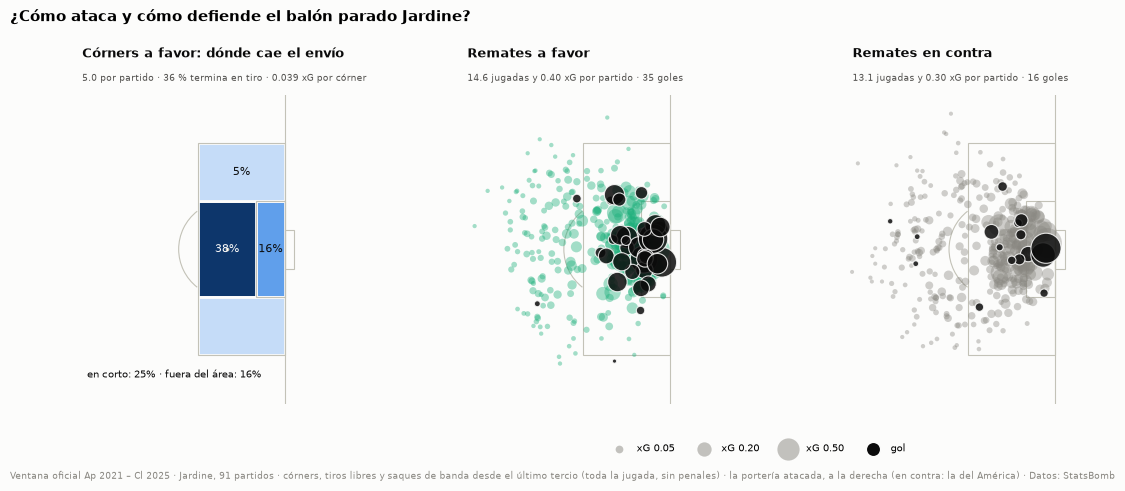

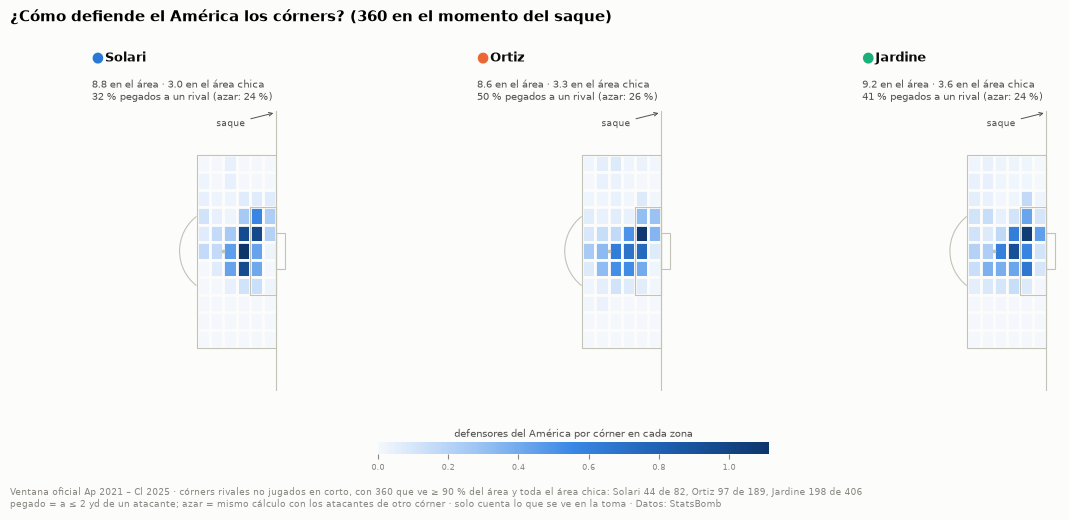

In [26]:
save(V.fig_set_pieces(deliv, bp, sps, scope, "¿Cómo ataca y cómo defiende el balón parado Jardine?"), "balon_parado")
save(V.fig_corner_defense(dgrid, cds, mk, scope, "¿Cómo defiende el América los córners? (360 en el momento del saque)"),
     "balon_parado_defensa")

In [27]:
b = bp.set_index(["coach", "lado", "kind"])
dz = deliv[(deliv.lado == "A favor") & (deliv.kind == "Córner") & (deliv.dimension == "Zona de entrega")].pivot(
    index="valor", columns="coach", values="share") * 100
zf = szone[(szone.lado == "A favor") & (szone.dimension == "zona")].pivot(index="valor", columns="coach", values="pct_xg")
xd = xgdef.set_index("coach")
r = rk_sp.set_index(["metrica", "coach"])
xpc = r.loc[("team_match_xg_per_corner", "Jardine")]
J, JC, JT, JB = (b.loc[("Jardine", "A favor", k)] for k in ["Total", "Córner", "Tiro libre", "Saque de banda"])
finding("3.8a Balón parado a favor", "¿Cómo ataca el América las jugadas a balón parado?",
    f"Jardine juega el córner en corto más que sus antecesores: {JC.pct_corto:.0f} % de sus córners (Ortiz "
    f"{b.loc[('Ortiz', 'A favor', 'Córner'), 'pct_corto']:.0f} %, Solari {b.loc[('Solari', 'A favor', 'Córner'), 'pct_corto']:.0f} %), y "
    f"cuando centra apunta al punto de penal ({dz.loc['Zona de penal', 'Jardine']:.0f} % de los envíos) más que al área chica "
    f"({dz.loc['Área chica', 'Jardine']:.0f} %; Ortiz {dz.loc['Área chica', 'Ortiz']:.0f} %). Con {JC.por_partido:.1f} córners por partido, "
    f"{JC.pct_tiro:.0f} % termina en tiro y cada uno vale {JC.xg_por_jugada:.3f} xG (Ortiz {b.loc[('Ortiz', 'A favor', 'Córner'), 'xg_por_jugada']:.3f}, "
    f"Solari {b.loc[('Solari', 'A favor', 'Córner'), 'xg_por_jugada']:.3f}), {abs(xpc.valor):.3f} xG "
    f"{'más' if xpc.valor > 0 else 'menos'} por córner que la media de la liga en su torneo (lugar {int(xpc.lugar)} de {int(xpc.de)} técnicos). Los tiros libres del último tercio "
    f"({JT.por_partido:.1f} por partido) terminan en tiro el {JT.pct_tiro:.0f} % de las veces y los saques de banda del último tercio "
    f"({JB.por_partido:.1f} por partido) solo el {JB.pct_tiro:.0f} %. En total, {J.xg_por_partido:.2f} xG y {J.goles:.0f} goles a balón parado en "
    f"{int((scope.coach == 'Jardine').sum())} partidos; {zf.loc['Área chica', 'Jardine']:.0f} % de ese xG se remata en el área chica. "
    f"¿Cuánto pesa el balón parado? Con la definición del marco (toda la posesión que abre un córner o un tiro libre propio, en "
    f"cualquier zona) es el {xd.loc['Jardine', 'pct_marco']:.0f} % de su xG sin penales; con las jugadas de esta sección, el "
    f"{xd.loc['Jardine', 'pct_jugadas']:.0f} %; y si solo se cuenta el remate que sale directo del envío, el "
    f"{xd.loc['Jardine', 'pct_directo']:.0f} % (Ortiz {xd.loc['Ortiz', 'pct_directo']:.0f} %, Solari {xd.loc['Solari', 'pct_directo']:.0f} %)"
    + (": la mayor parte de su peligro a balón parado es la segunda jugada." if J.pct_xg_directo < 50 else "."),
    ["balon_parado.png"])

**¿Cómo ataca el América las jugadas a balón parado?**

**Hallazgo.** Jardine juega el córner en corto más que sus antecesores: 25 % de sus córners (Ortiz 13 %, Solari 9 %), y cuando centra apunta al punto de penal (38 % de los envíos) más que al área chica (16 %; Ortiz 27 %). Con 5.0 córners por partido, 36 % termina en tiro y cada uno vale 0.039 xG (Ortiz 0.034, Solari 0.035), 0.006 xG más por córner que la media de la liga en su torneo (lugar 16 de 70 técnicos). Los tiros libres del último tercio (2.5 por partido) terminan en tiro el 40 % de las veces y los saques de banda del último tercio (7.1 por partido) solo el 11 %. En total, 0.40 xG y 35 goles a balón parado en 91 partidos; 35 % de ese xG se remata en el área chica. ¿Cuánto pesa el balón parado? Con la definición del marco (toda la posesión que abre un córner o un tiro libre propio, en cualquier zona) es el 37 % de su xG sin penales; con las jugadas de esta sección, el 26 %; y si solo se cuenta el remate que sale directo del envío, el 7 % (Ortiz 10 %, Solari 14 %): la mayor parte de su peligro a balón parado es la segunda jugada.

In [28]:
zc = szone[(szone.lado == "En contra") & (szone.dimension == "zona")].pivot(index="valor", columns="coach", values="pct_xg")
pc = szone[(szone.lado == "En contra") & (szone.dimension == "palo")].pivot(index="valor", columns="coach", values="pct_xg")
c_ = cds.set_index("coach")
m_ = mk.set_index("coach")
K, KC = b.loc[("Jardine", "En contra", "Total")], b.loc[("Jardine", "En contra", "Córner")]
spc = r.loc[("team_match_sp_xg_conceded", "Jardine")]
cpc = r.loc[("team_match_xg_per_corner_conceded", "Jardine")]
man = m_.loc["Jardine", "pct_pegados"] > m_.loc["Jardine", "azar_p95"]
top_zone = zc["Jardine"].idxmax()
finding("3.8b Balón parado en contra", "¿Cómo defiende el América las jugadas a balón parado?",
    f"En contra, Jardine concede {K.por_partido:.1f} jugadas y {K.xg_por_partido:.2f} xG por partido a balón parado "
    f"({K.goles:.0f} goles; Ortiz {b.loc[('Ortiz', 'En contra', 'Total'), 'xg_por_partido']:.2f} xG, Solari "
    f"{b.loc[('Solari', 'En contra', 'Total'), 'xg_por_partido']:.2f}). Lo que más le cuesta es el córner: {KC.por_partido:.1f} por partido "
    f"(Ortiz {b.loc[('Ortiz', 'En contra', 'Córner'), 'por_partido']:.1f}) a {KC.xg_por_jugada:.3f} xG cada uno. Frente a la liga de su "
    f"torneo concede {abs(spc.valor):.2f} xG {'menos' if spc.valor < 0 else 'más'} a balón parado por partido (lugar {int(spc.lugar)} "
    f"de {int(spc.de)} en conceder poco), {'pero' if (spc.valor < 0) != (cpc.valor < 0) else 'y'} {abs(cpc.valor):.3f} xG {'menos' if cpc.valor < 0 else 'más'} por córner (lugar "
    f"{int(cpc.lugar)} de {int(cpc.de)}). Zona vulnerable: la {top_zone.lower()}, de donde sale el "
    f"{zc.loc[top_zone, 'Jardine']:.0f} % del xG que concede ({zc.loc['Área chica', 'Jardine']:.0f} % desde el área chica, frente a "
    f"{zc.loc['Área chica', 'Ortiz']:.0f} % con Ortiz); en córners, el primer palo concentra el {pc.loc['Primer palo', 'Jardine']:.0f} %. "
    f"Con 360 en el momento del saque ({int(c_.loc['Jardine', 'utiles'])} de {int(c_.loc['Jardine', 'corners'])} córners con el área a la vista), "
    f"defiende con {c_.loc['Jardine', 'defensores_area_media']:.0f} jugadores en el área, {c_.loc['Jardine', 'defensores_chica']:.1f} de ellos en el área chica, "
    f"y el {m_.loc['Jardine', 'pct_pegados']:.0f} % está pegado a un rival frente a {m_.loc['Jardine', 'pct_pegados_azar']:.0f} % que daría el azar: "
    + ("esquema mixto, una base zonal en el área chica con marcas individuales " if man else "no hay señal clara de marcaje individual: domina la zona ")
    + f"(Ortiz marcaba más al hombre, {m_.loc['Ortiz', 'pct_pegados']:.0f} %; Solari, {m_.loc['Solari', 'pct_pegados']:.0f} %). En el eje "
    f"\"Balón parado\" del ADN, que resta lo concedido a lo generado, Jardine está en el percentil {adn.loc['Jardine', 'Balón parado']:.0f} "
    f"de la liga (Ortiz {adn.loc['Ortiz', 'Balón parado']:.0f}, Solari {adn.loc['Solari', 'Balón parado']:.0f}).",
    ["balon_parado.png", "balon_parado_defensa.png"])

**¿Cómo defiende el América las jugadas a balón parado?**

**Hallazgo.** En contra, Jardine concede 13.1 jugadas y 0.30 xG por partido a balón parado (16 goles; Ortiz 0.25 xG, Solari 0.23). Lo que más le cuesta es el córner: 4.8 por partido (Ortiz 3.9) a 0.035 xG cada uno. Frente a la liga de su torneo concede 0.03 xG menos a balón parado por partido (lugar 23 de 70 en conceder poco), pero 0.003 xG más por córner (lugar 49 de 70). Zona vulnerable: la zona de penal, de donde sale el 52 % del xG que concede (29 % desde el área chica, frente a 41 % con Ortiz); en córners, el primer palo concentra el 53 %. Con 360 en el momento del saque (198 de 406 córners con el área a la vista), defiende con 9 jugadores en el área, 3.6 de ellos en el área chica, y el 41 % está pegado a un rival frente a 24 % que daría el azar: esquema mixto, una base zonal en el área chica con marcas individuales (Ortiz marcaba más al hombre, 50 %; Solari, 32 %). En el eje "Balón parado" del ADN, que resta lo concedido a lo generado, Jardine está en el percentil 74 de la liga (Ortiz 79, Solari 62).

## Resumen de hallazgos (§3.2, §3.3, §3.4 y §3.8)

Se guardan en `data/gold/analysis/story_hallazgos.parquet` para que el reporte HTML los tome tal cual.

In [29]:
hall = pd.DataFrame(H)
S.save_story(hall, "hallazgos")
for h in H:
    display(Markdown(f"- **{h['pregunta']}** {h['hallazgo']}"))

- **¿Cómo sale el América desde atrás?** Con Jardine el América sale jugando: saca en corto el 45 % de sus saques de meta, frente a 31 % con Ortiz y 33 % con Solari. Ese pase corto lo recibe un mediocentro que baja a pedirla en el 44 % de los casos (Ortiz 20 %, Solari 4 %, que se la daban casi siempre a un central). Es una idea de control, no un atajo al gol: 66 % de esas salidas cortas llega a campo rival (Ortiz 77 %; en largo, 74 %) y generan 0.7 xG por cada 100 salidas, lo mismo que en largo.

- **¿Por dónde progresa el América?** Jardine progresa por dentro y entra por fuera. El 42 % de sus pases progresivos termina en el carril central, pero al último tercio llega sobre todo por las bandas: 21.1 entradas por partido por la izquierda y 17.9 por la derecha, frente a 9.3 por el centro. Pisa el área 14.7 veces por partido, como Ortiz (15.0) y 48 % más que Solari (9.9); 41 % de esas entradas son conduciendo (Ortiz 38 %, Solari 36 %).

- **¿Cómo genera ocasiones el América?** Jardine no tira más, tira mejor: 13.2 tiros y 1.52 xG por partido sin penales (Ortiz 15.9 tiros y 1.57 xG), con 0.12 xG por tiro frente a 0.10 de Ortiz y 0.08 de Solari, y 65 % de sus tiros dentro del área. De su xG, 26 % nace del juego posicional, 38 % de transiciones y 37 % de balón parado. Su jugada distintiva es el pase atrás al área: 15 % del xG (Ortiz 10 %, Solari 8 %); el centro pesa menos que con Solari (17 % frente a 28 %).

- **¿Quién conecta con quién en el 11 de Jardine?** En el 4-2-3-1 más usado (41 de 91 partidos), el balón pasa por el doble pivote: Álvaro Fidalgo (28 pases por partido) y Jonathan dos Santos (27) son los que más pases dan. Las conexiones más usadas (pases por partido juntos) son Jonathan dos Santos–Álvaro Fidalgo (21); Cristian Calderón–Álvaro Fidalgo (12); Igor Lichnovsky–Kevin Álvarez (10). El juego se carga a la izquierda: los jugadores de ese lado dan 56 % de los pases del 11.

- **¿Dónde recupera el balón el América?** Jardine no roba más arriba que sus antecesores: recupera 52 balones por partido a una altura media de 42 yd de su portería (Solari 43, Ortiz 42) y 24 % en campo rival (Solari 24 %, Ortiz 25 %). Su zona de robo es el centro de su propio campo, justo delante del área (6.4 recuperaciones por partido entre las 20 y las 40 yd), y 40 % de lo que recupera se convierte en transición (Solari 37 %, Ortiz 39 %).

- **¿Presiona más o menos que la liga?** Jardine no asfixia al rival: le deja dar 1.9 pases más por cada intento de recuperación que la media de la liga en el mismo torneo (PPDA; el 11.º más alto de 70 técnicos), mientras Ortiz presionaba más que la liga (-0.6). Con los eventos se ve igual: PPDA mediano de 13.8 frente a 11.4 de Ortiz y 10.2 de Solari. Pero cuando presiona, lo hace arriba: 1.7 puntos más de sus presiones en campo rival que la liga (más que 71 de cada 100 técnicos), y aunque tras perder el balón contrapresiona menos que la liga (2.3 veces menos por partido), recupera un poco más así (0.2 balones más por partido; más que 74 de cada 100 técnicos).

- **¿Cómo le va al América en las transiciones?** Jardine gana el intercambio: 20.6 transiciones a favor por partido que valen 0.57 xG, frente a 18.1 del rival que valen 0.31 xG: 1.8 veces más peligro a favor que en contra (Ortiz 1.7, Solari 0.9). Las suyas llegan al último tercio en unos 6 s (las del rival, en 5 s). Frente a la liga concede pocos contragolpes: 0.89 tiros de contraataque por partido, 0.24 menos que la media de su torneo (14.º que menos de 70 técnicos).

- **¿Qué tan alto y qué tan junto defiende el América?** Jardine defiende un poco más atrás y más junto que Ortiz. Con el balón entre las 40 y las 60 yd (bloque medio), su última línea está a 32 yd de su portería (Ortiz 34, Solari 33; por partido, -1.7 yd frente a Ortiz, IC 90 % -2.5 a -0.8) y su bloque mide 20 yd de largo, 2.1 yd menos que el de Ortiz (IC 90 % 1.5 a 2.7). Donde más se nota es atrás: en bloque bajo junta a sus 8 jugadores en 15 yd (Ortiz 18, Solari 15) con 9 yd entre líneas. El ancho casi no cambia (41 yd en bloque medio). Tras perder el balón su línea queda más atrás (40 yd frente a 45 de Ortiz), pero sobre todo porque pierde el balón más atrás (a 54 yd frente a 59): la línea queda a 12 yd del balón (Ortiz 11), casi lo mismo. Encaja con su presión media (§3.3): no adelanta la defensa para asfixiar, la junta. Límite: solo cuenta lo que se ve en la toma; 32 % de los pases rivales de Jardine dan un frame útil, y solo 16 % en bloque alto (la cámara sigue al balón, lejos de la defensa).

- **¿Cómo ataca el América las jugadas a balón parado?** Jardine juega el córner en corto más que sus antecesores: 25 % de sus córners (Ortiz 13 %, Solari 9 %), y cuando centra apunta al punto de penal (38 % de los envíos) más que al área chica (16 %; Ortiz 27 %). Con 5.0 córners por partido, 36 % termina en tiro y cada uno vale 0.039 xG (Ortiz 0.034, Solari 0.035), 0.006 xG más por córner que la media de la liga en su torneo (lugar 16 de 70 técnicos). Los tiros libres del último tercio (2.5 por partido) terminan en tiro el 40 % de las veces y los saques de banda del último tercio (7.1 por partido) solo el 11 %. En total, 0.40 xG y 35 goles a balón parado en 91 partidos; 35 % de ese xG se remata en el área chica. ¿Cuánto pesa el balón parado? Con la definición del marco (toda la posesión que abre un córner o un tiro libre propio, en cualquier zona) es el 37 % de su xG sin penales; con las jugadas de esta sección, el 26 %; y si solo se cuenta el remate que sale directo del envío, el 7 % (Ortiz 10 %, Solari 14 %): la mayor parte de su peligro a balón parado es la segunda jugada.

- **¿Cómo defiende el América las jugadas a balón parado?** En contra, Jardine concede 13.1 jugadas y 0.30 xG por partido a balón parado (16 goles; Ortiz 0.25 xG, Solari 0.23). Lo que más le cuesta es el córner: 4.8 por partido (Ortiz 3.9) a 0.035 xG cada uno. Frente a la liga de su torneo concede 0.03 xG menos a balón parado por partido (lugar 23 de 70 en conceder poco), pero 0.003 xG más por córner (lugar 49 de 70). Zona vulnerable: la zona de penal, de donde sale el 52 % del xG que concede (29 % desde el área chica, frente a 41 % con Ortiz); en córners, el primer palo concentra el 53 %. Con 360 en el momento del saque (198 de 406 córners con el área a la vista), defiende con 9 jugadores en el área, 3.6 de ellos en el área chica, y el 41 % está pegado a un rival frente a 24 % que daría el azar: esquema mixto, una base zonal en el área chica con marcas individuales (Ortiz marcaba más al hombre, 50 %; Solari, 32 %). En el eje "Balón parado" del ADN, que resta lo concedido a lo generado, Jardine está en el percentil 74 de la liga (Ortiz 79, Solari 62).

## Alcance y límites

- **Balón parado** (§3.2) se define por cómo nace la posesión (marco): la abre el saque del propio equipo e incluye toda
  la jugada que sigue a un córner o a un tiro libre en cualquier zona, no solo el primer remate. Por eso pesa tanto en el xG; §3.8 muestra la cifra con
  el remate directo.
- **Balón parado con 360 (§3.8)**: "pegado" (≤ 2 yd) no es lo mismo que "marcando": la prueba contra el azar dice
  si hay más cercanía de la que darían posiciones fijas, no quién marca a quién. Solo la mitad de los córners rivales
  tienen el área a la vista en el momento del saque.
- **Recuperaciones y transiciones** se ubican donde empieza la posesión; si la recuperación no genera una posesión nueva
  (p. ej., un despeje que vuelve al rival), no cuenta.
- **Comparación con la liga** solo con métricas de StatsBomb que existen para todos los equipos; las métricas propias
  del marco (con eventos) solo existen para el América y se comparan entre técnicos del América.
- **Época**: las métricas de la liga se ajustan por torneo; las del marco (Solari 2021–22 frente a Jardine 2023–25) no se
  pueden ajustar sin eventos de toda la liga, así que las diferencias pequeñas entre técnicos no se deben sobreleer.
- **Red de pases**: una foto del 11 más usado (menos de la mitad de los partidos de Jardine), hasta el primer cambio; no
  representa a los partidos con otros sistemas.
- **360 (§3.4)**: solo cuenta lo que se ve en la toma. Un frame cuenta si se ven ≥ 8 jugadores de campo del
  América y ≥ 5 yd detrás del más retrasado; aun así, en bloque alto la cámara sigue al balón y pocos frames son
  útiles, así que esa fase es la menos confiable. Las líneas se definen por orden de profundidad (4 + 4), no por
  posición nominal: con línea de 5 o carrileros muy bajos, la "segunda línea" mezcla a un defensor. Solo hay 360
  del América: no hay comparación con la liga.